# Part 1: Breast cancer prediction

using a breast cancer dataset to predict whether a tumor is malignant (cancerous) or benign (non-cancerous).

The breast cancer dataset contains measurements of cell nuclei from breast mass samples. Each sample has 30 features (like radius, texture, perimeter, etc.) and a target label indicating whether the tumor is malignant (1) or benign (0).

Your task is to build a model that can predict whether a new tumor sample is malignant or benign based on these measurements. You should start a new notebook and copy the code templates provided in each step. You are encouraged to run the code and experiment with it and are allowed to change the parameters to see how it affects the results. After each step, write your conclusions and observations.

### Step 1: Setting Up and Loading Data


In [9]:
"""
Breast Cancer Prediction with KNN
Author: [Your Name]
Description: Predict whether a breast tumor is malignant or benign using KNN
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report



In [10]:
# Load the breast cancer dataset
print("Loading breast cancer dataset...")
from sklearn.datasets import load_breast_cancer
cancer_data = load_breast_cancer()


Loading breast cancer dataset...


In [11]:
type(cancer_data)
#sklearn.utils._bunch.Bunch is a dictionary-like container used by scikit-learn to package a dataset and its metadata. You can access its entries either like dictionary keys or as attributes:


sklearn.utils._bunch.Bunch

In [12]:
cancer_df = pd.DataFrame(cancer_data.data, columns=cancer_data.feature_names)
cancer_df["target"] = cancer_data.target

cancer_df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [21]:
cancer_df.shape 

(569, 31)

In [15]:
feature_names = cancer_df.drop(columns="target").columns
print("Feature names:")
print(feature_names.tolist())

Feature names:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']


In [43]:
target_names = pd.Series(cancer_data.target).map(
{1: "malignant", 0: "benign"})

target_names.value_counts()

# malignant means bösartig, benign means gutartig



malignant    357
benign       212
Name: count, dtype: int64

### Step 2: Data Exploration

In [44]:
#look at basic statistics for the features

features=cancer_df.drop(columns="target")
features.describe()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [45]:
cancer_df.isnull().sum() # check for missing values

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
target_label               0
dtype: int64

In [46]:
missing = cancer_df.isnull().sum()
if missing.sum() == 0:
    print("✓ No missing values found!")
else:
    print(missing[missing > 0])

✓ No missing values found!


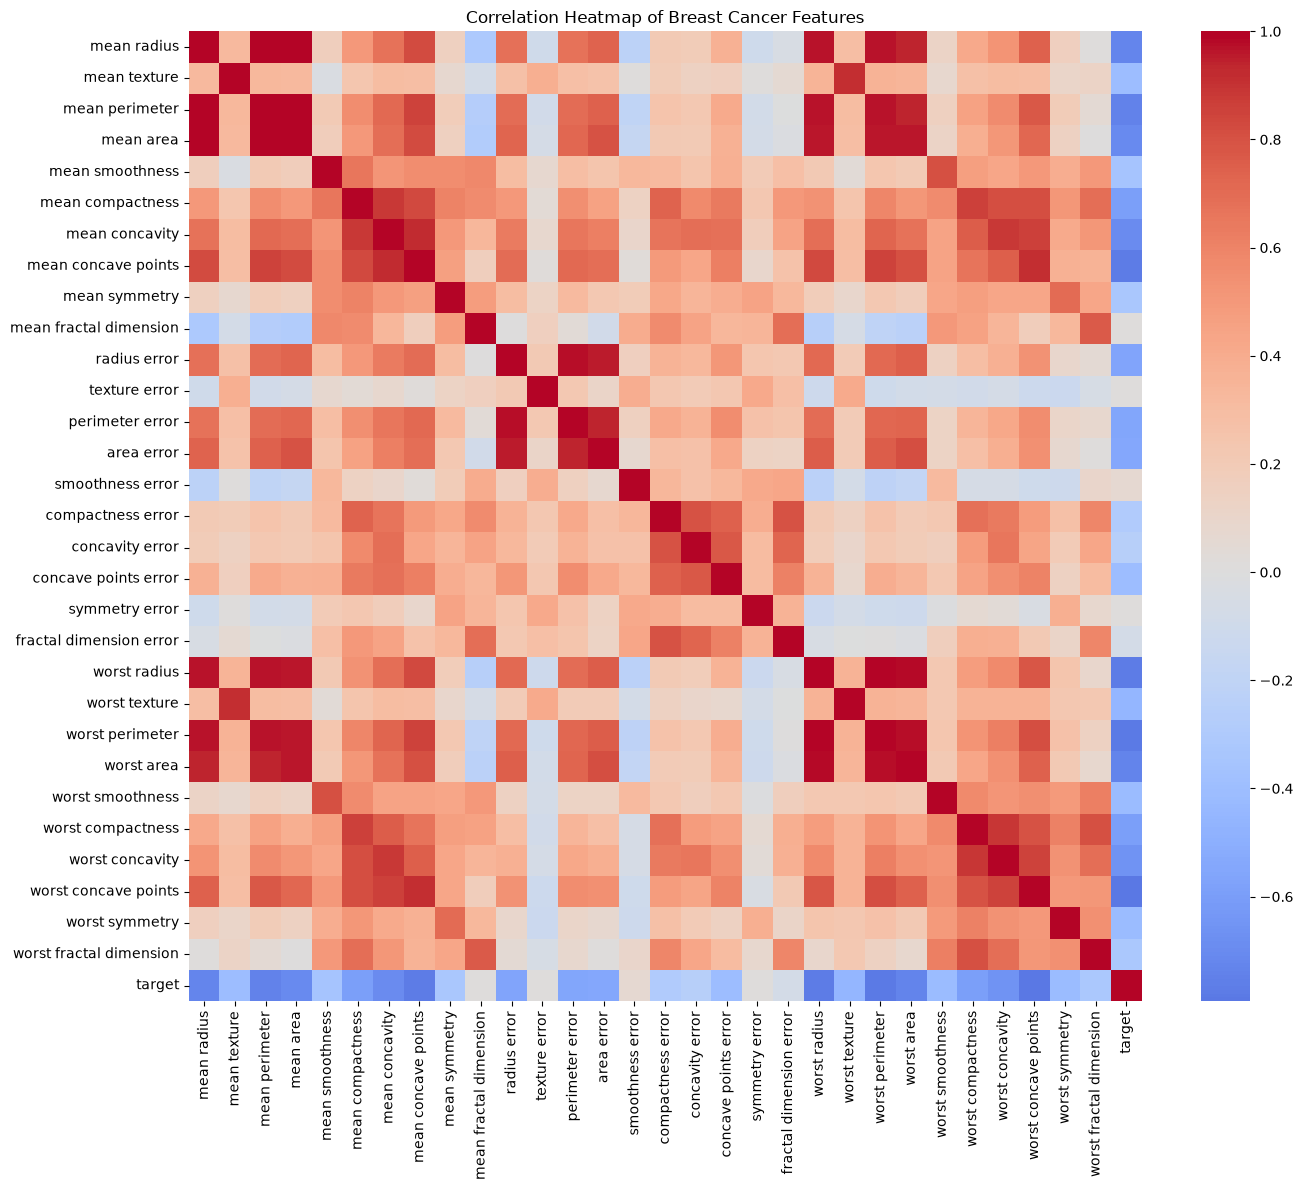

In [47]:
import seaborn as sns
import matplotlib.pyplot as plt

correlation_matrix = cancer_df.corr(numeric_only=True)
plt.figure(figsize=(14, 12))
sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Correlation Heatmap of Breast Cancer Features")
plt.tight_layout()
plt.show()

In [48]:
cancer_df.groupby("target").mean(numeric_only=True)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
target,,,,,,,,,,,,,,,,,,,,,
0,17.462830,21.604906,115.365377,978.376415,0.102898,0.145188,0.160775,0.087990,0.192909,0.062680,...,21.134811,29.318208,141.370330,1422.286321,0.144845,0.374824,0.450606,0.182237,0.323468,0.091530
1,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,...,13.379801,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442


Saved visualization to 'feature_distributions.png'


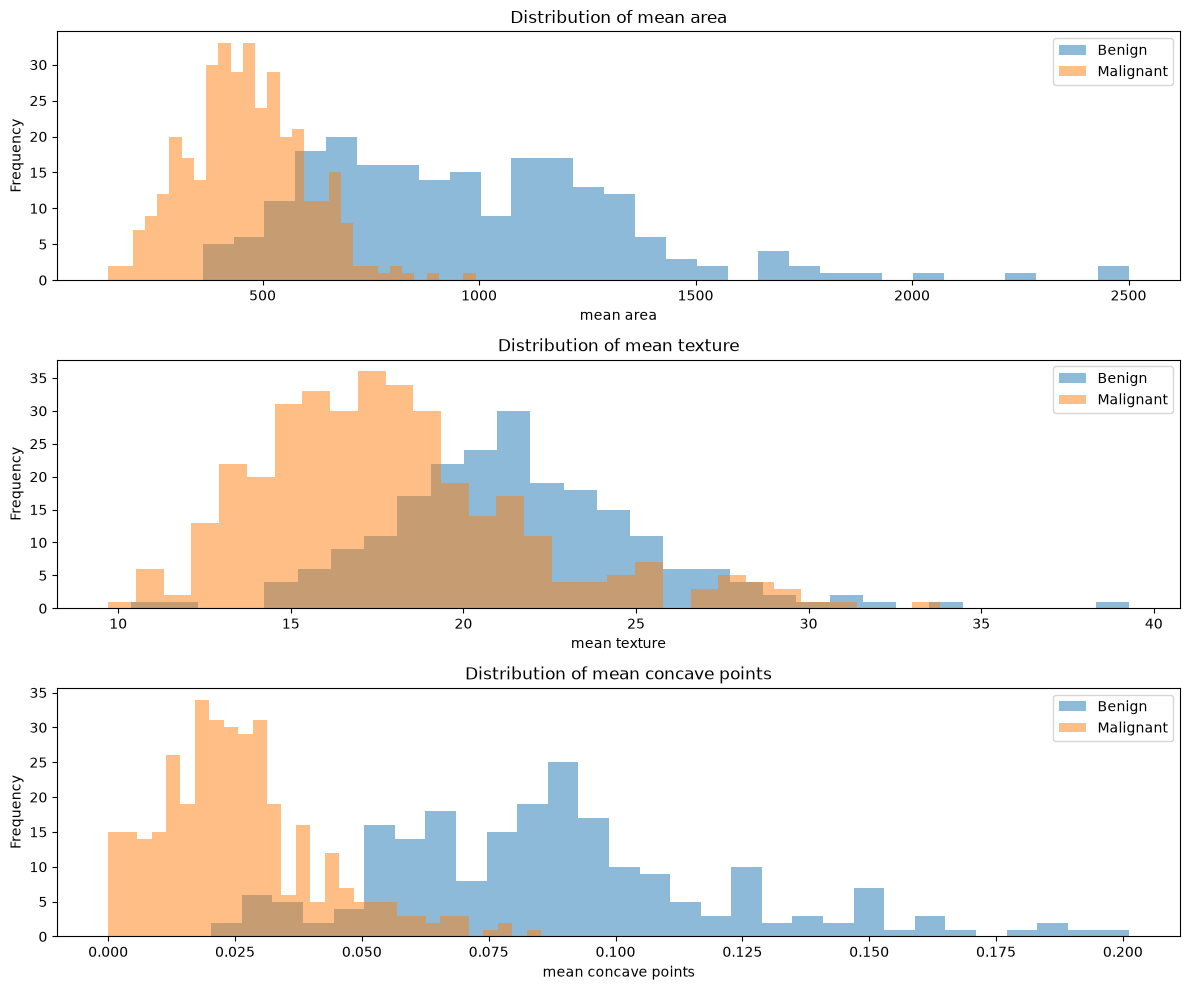

In [50]:
# Select a few representative features to visualize
key_features = ['mean area', 'mean texture', 'mean concave points']

fig, axes = plt.subplots(3,1, figsize=(12, 10))
axes = axes.ravel()

for idx, feature in enumerate(key_features):
    axes[idx].hist(cancer_df[cancer_df['target'] == 0][feature], alpha=0.5, label='Benign', bins=30)
    axes[idx].hist(cancer_df[cancer_df['target'] == 1][feature], alpha=0.5, label='Malignant', bins=30)
    axes[idx].set_xlabel(feature)
    axes[idx].set_ylabel('Frequency')
    axes[idx].set_title(f'Distribution of {feature}')
    axes[idx].legend()

plt.tight_layout()
plt.savefig('feature_distributions.png', dpi=150, bbox_inches='tight')
print("Saved visualization to 'feature_distributions.png'")
plt.show()

### Step 3: Splitting the Data


In [58]:
X = cancer_df.select_dtypes(include="number").drop(columns="target")
y = cancer_df["target"]

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

Features shape: (569, 30)
Target shape: (569,)


In [59]:
# Split into training and testing sets
# random_state ensures reproducibility
# stratify=y ensures both sets have similar class distribution
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42, 
    stratify=y
)

In [60]:
print(f"Training set size: {X_train.shape[0]} samples")
print(f"Test set size: {X_test.shape[0]} samples")
print(f"Training features: {X_train.shape[1]}")
print(f"Test features: {X_test.shape[1]}")

Training set size: 455 samples
Test set size: 114 samples
Training features: 30
Test features: 30


In [61]:
# Verify class distribution in both sets
print("\nTraining set target distribution:")
print(y_train.value_counts())
print(f"  Benign (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)")
print(f"  Malignant (1): {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")

print("\nTest set target distribution:")
print(y_test.value_counts())
print(f"  Benign (0): {(y_test == 0).sum()} ({(y_test == 0).mean()*100:.1f}%)")
print(f"  Malignant (1): {(y_test == 1).sum()} ({(y_test == 1).mean()*100:.1f}%)")



Training set target distribution:
target
1    285
0    170
Name: count, dtype: int64
  Benign (0): 170 (37.4%)
  Malignant (1): 285 (62.6%)

Test set target distribution:
target
1    72
0    42
Name: count, dtype: int64
  Benign (0): 42 (36.8%)
  Malignant (1): 72 (63.2%)


### Step 4: Training the KNN Model


In [62]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


**Explanation:**
KNN (K-Nearest Neighbors) is a simple but effective classification algorithm. When making a prediction for a new sample, it:
1. Finds the K nearest training samples (based on feature similarity)
2. Looks at the labels of those K neighbors
3. Predicts the most common label among those neighbors

### Step 5: Making Predictions

In [64]:
y_train_pred = knn.predict(X_train)
y_test_pred = knn.predict(X_test)
print(f"\nTraining predictions: {len(y_train_pred)}")
print(f"Test predictions: {len(y_test_pred)}")


Training predictions: 455
Test predictions: 114


In [70]:
label = {0: "Malignant", 1: "Benign"}

knn_results = X_test.copy()
knn_results["Actual"] = pd.Series(y_test.to_numpy(), index=X_test.index).map(label)
knn_results["Predicted"] = pd.Series(y_test_pred, index=X_test.index).map(label)
knn_results["Correct?"] = np.where(
    y_test.to_numpy() == y_test_pred, "✅", "❌"
)

display(knn_results)  # Shows every test sample

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Actual,Predicted,Correct?
256,19.55,28.77,133.60,1207.0,0.09260,0.20630,0.17840,0.11440,0.1893,0.06232,...,1926.0,0.1281,0.53290,0.4251,0.19410,0.2818,0.10050,Malignant,Malignant,✅
428,11.13,16.62,70.47,381.1,0.08151,0.03834,0.01369,0.01370,0.1511,0.06148,...,421.1,0.1030,0.06219,0.0458,0.04044,0.2383,0.07083,Benign,Benign,✅
501,13.82,24.49,92.33,595.9,0.11620,0.16810,0.13570,0.06759,0.2275,0.07237,...,788.0,0.1794,0.39660,0.3381,0.15210,0.3651,0.11830,Malignant,Malignant,✅
363,16.50,18.29,106.60,838.1,0.09686,0.08468,0.05862,0.04835,0.1495,0.05593,...,1009.0,0.1338,0.16790,0.1663,0.09123,0.2394,0.06469,Benign,Malignant,❌
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,2027.0,0.1410,0.21130,0.4107,0.22160,0.2060,0.07115,Malignant,Malignant,✅
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,20.26,23.03,132.40,1264.0,0.09078,0.13130,0.14650,0.08683,0.2095,0.05649,...,1750.0,0.1190,0.35390,0.4098,0.15730,0.3689,0.08368,Malignant,Malignant,✅
128,15.10,16.39,99.58,674.5,0.11500,0.18070,0.11380,0.08534,0.2001,0.06467,...,762.6,0.1386,0.28830,0.1960,0.14230,0.2590,0.07779,Benign,Benign,✅
257,15.32,17.27,103.20,713.3,0.13350,0.22840,0.24480,0.12420,0.2398,0.07596,...,928.8,0.1765,0.45030,0.4429,0.22290,0.3258,0.11910,Malignant,Malignant,✅
228,12.62,23.97,81.35,496.4,0.07903,0.07529,0.05438,0.02036,0.1514,0.06019,...,624.0,0.1227,0.34540,0.3911,0.11800,0.2826,0.09585,Benign,Benign,✅


### Step 6: Evaluating Model Performance


In [72]:
# Calculate metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)
test_precision = precision_score(y_test, y_test_pred)
test_recall = recall_score(y_test, y_test_pred)
test_confusion = confusion_matrix(y_test, y_test_pred)

print("=== Model Performance ===")
print(f"\nTraining Accuracy: {train_accuracy:.4f} ({train_accuracy*100:.2f}%)")
print(f"Test Accuracy: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
print(f"\nTest Precision: {test_precision:.4f}")
print(f"Test Recall: {test_recall:.4f}")

print("\n=== Confusion Matrix ===")
print("                Predicted")
print("              Benign  Malignant")
print(f"Actual Benign    {test_confusion[0,0]:4d}      {test_confusion[0,1]:4d}")
print(f"      Malignant  {test_confusion[1,0]:4d}      {test_confusion[1,1]:4d}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_test_pred, target_names=cancer_data.target_names))



=== Model Performance ===

Training Accuracy: 0.9473 (94.73%)
Test Accuracy: 0.9123 (91.23%)

Test Precision: 0.9429
Test Recall: 0.9167

=== Confusion Matrix ===
                Predicted
              Benign  Malignant
Actual Benign      38         4
      Malignant     6        66

=== Classification Report ===
              precision    recall  f1-score   support

   malignant       0.86      0.90      0.88        42
      benign       0.94      0.92      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.91      0.91       114
weighted avg       0.91      0.91      0.91       114



### Step 7: Experimenting with Different K Values


,k,train_accuracy,test_accuracy
0,1,1.000000,0.938596
1,3,0.978022,0.982456
2,5,0.973626,0.956140
3,7,0.975824,0.973684
4,9,0.973626,0.973684
5,11,0.971429,0.973684


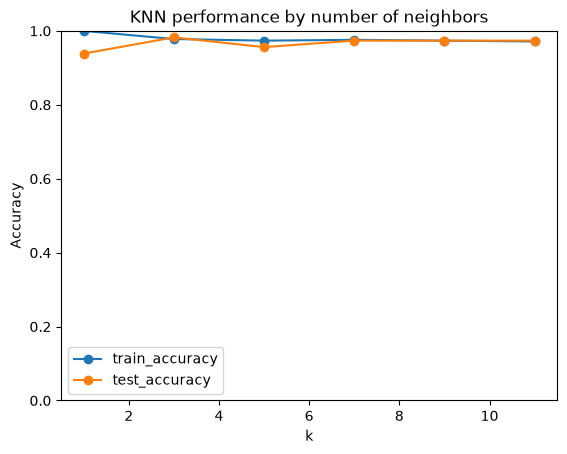

In [76]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

k_values = [1, 3, 5, 7, 9, 11]

results = []

for k in k_values:
    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k)
    )
    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    results.append({
        "k": k,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred)
    })

results_df = pd.DataFrame(results)
display(results_df)

results_df.set_index("k")[["train_accuracy", "test_accuracy"]].plot(
    marker="o",
    ylim=(0, 1),
    ylabel="Accuracy",
    title="KNN performance by number of neighbors"
)
plt.show()

## Part 2: Unguided Exercise - Customer Churn Prediction

### Background

Now it's your turn! You'll work independently to predict customer churn for a telecommunications company. Customer churn is when customers stop using a company's services. Predicting churn helps companies take proactive measures to retain customers.

**Dataset:** Telco Customer Churn Dataset
- **Source:** [Kaggle - Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
- **Alternative Download:** The dataset is also available on various data science platforms

**Dataset Description:**
- Contains information about 7,043 customers
- Features include: customer demographics, services subscribed, account information
- Target: Whether the customer churned (Yes/No)

#### Step 1: Load and Explore the Data
- Download the Telco Customer Churn dataset
- Load it into a pandas DataFrame
- Explore the dataset: shape, columns, data types, missing values
- Check the target distribution (how many churned vs. didn't churn)
- Visualize some key features


In [93]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0.0,Yes,No,1.0,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0.0,No,No,34.0,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0.0,No,No,2.0,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0.0,No,No,45.0,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0.0,No,No,2.0,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [101]:
df.shape

(7044, 21)

In [94]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7044 entries, 0 to 7043
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   float64
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   float64
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [95]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [99]:
df.Churn.value_counts() # categorical target variable, 0 = No churn, 1 = Churn

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [103]:
df.tenure.value_counts()

tenure
1.0     613
72.0    362
2.0     238
3.0     200
4.0     176
       ... 
28.0     57
39.0     56
44.0     51
36.0     50
0.0      11
Name: count, Length: 73, dtype: int64

In [114]:
df.TotalCharges.value_counts()

TotalCharges
20.2      11
          11
19.75      9
19.9       8
20.05      8
          ..
1990.5     1
7362.9     1
346.45     1
306.6      1
6844.5     1
Name: count, Length: 6531, dtype: int64

In [115]:
X["TotalCharges"] = pd.to_numeric(X["TotalCharges"], errors="coerce")

KeyError: 'TotalCharges'

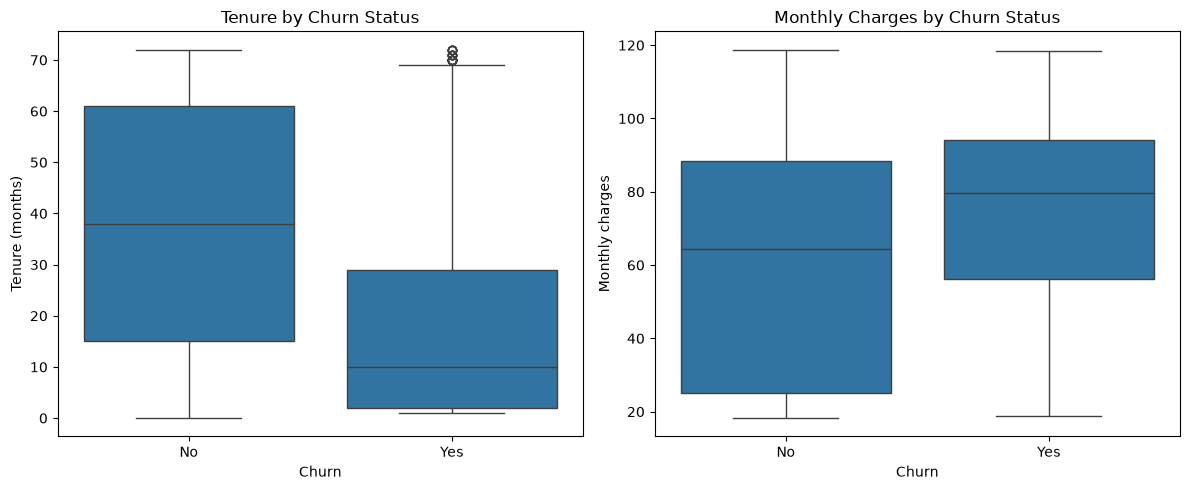

In [117]:
#tenure is how long the customer has been with the company, measured in months. 
# MonthlyCharges is the amount charged per month. 
# These boxplots compare each feature for customers who churned (Yes) and those who stayed (No):


import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(data=df, x="Churn", y="tenure", order=["No", "Yes"], ax=axes[0])
axes[0].set_title("Tenure by Churn Status")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Tenure (months)")

sns.boxplot(data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], ax=axes[1])
axes[1].set_title("Monthly Charges by Churn Status")
axes[1].set_xlabel("Churn")
axes[1].set_ylabel("Monthly charges")


plt.tight_layout()
plt.show()

#### Step 2: Data Preprocessing
- Handle missing values (if any)
- Convert categorical variables to numeric (use encoding techniques)
- Select relevant features for modeling
- Separate features (X) from target (y)
- Convert target to binary (0/1) if needed

In [109]:
df.isna().sum()

customerID          1
gender              1
SeniorCitizen       1
Partner             1
Dependents          1
tenure              1
PhoneService        1
MultipleLines       1
InternetService     1
OnlineSecurity      1
OnlineBackup        1
DeviceProtection    1
TechSupport         1
StreamingTV         1
StreamingMovies     1
Contract            1
PaperlessBilling    1
PaymentMethod       1
MonthlyCharges      1
TotalCharges        1
Churn               1
dtype: int64

df.isna()

In [112]:
df[df.isna().any(axis=1)]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [113]:
df = df.dropna()

In [136]:
y = df["Churn"].map({"No": 0, "Yes": 1})

# Input features (exclude target and customer ID)
X = df.drop(columns=["Churn", "customerID"], errors="ignore")

In [137]:
print(len(X), len(y)) 


7043 7043


In [138]:
if "TotalCharges" in X.columns:
    charges = X["TotalCharges"].astype("string").str.strip()
    charges = charges.replace("", "0")
    X["TotalCharges"] = pd.to_numeric(charges)

X = pd.get_dummies(X, drop_first=True, dtype=int)

print("Missing values:", X.isna().sum().sum())

Missing values: 0


#### Step 3: Split the Data
- Split into training (80%) and testing (20%) sets
- Use `stratify` to maintain class distribution
- Set `random_state=42` for reproducibility

In [141]:
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, mutual_info_classif

# X: encoded features; y: Churn encoded as 0/1
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



#### Step 4: Train a KNN Model
- Create a KNN classifier
- Start with `n_neighbors=5`
- Train the model on the training data

In [142]:
selector = SelectKBest(score_func=mutual_info_classif, k=5)
X_train_selected = selector.fit_transform(X_train, y_train)
X_test_selected = selector.transform(X_test)

selected_features = X.columns[selector.get_support()]
print("Selected features:", selected_features.tolist())

Selected features: ['tenure', 'MonthlyCharges', 'InternetService_Fiber optic', 'Contract_Two year', 'PaymentMethod_Electronic check']


In [148]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

knn_pipeline = Pipeline([
    ("feature_selection", SelectKBest(
        score_func=mutual_info_classif,
        k=5
    )),
    ("scaler", StandardScaler()), #Standardize those features so differences in scale don’t dominate KNN’s distance calculations.
    ("knn", KNeighborsClassifier(n_neighbors=5)) #Fit KNN with five neighbors.
])

knn_pipeline.fit(X_train, y_train)



,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_selection', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['SeniorCitizen','tenure','MonthlyCharges',..., 'PaymentMethod_Credit card (automatic)','PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"score_func score_func: callable, default=f_classifFunction taking two arrays X and y, and returning a pair of arrays(scores, pvalues) or a single array with scores.Default is f_classif (see below ""See Also""). The default function onlyworks with classification tasks... versionadded:: 0.18",<function mut...0025BA5AD3B00>
,"k k: int or ""all"", default=10Number of top features to select.The ""all"" option bypasses selection, for use in a parameter search.",5
Name,Type,Value


#### Step 5: Make Predictions and Evaluate
- Make predictions on the test set
- Calculate accuracy, precision, and recall
- Create a confusion matrix
- Generate a classification report
- Interpret the results

Accuracy:  77.00%
Precision: 57.72%
Recall:    50.00%


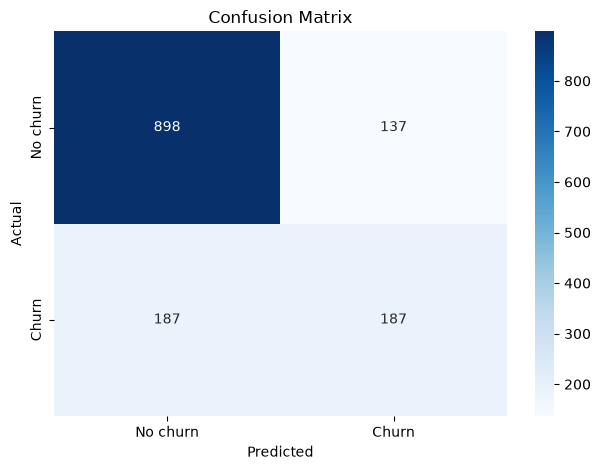

              precision    recall  f1-score   support

    No churn       0.83      0.87      0.85      1035
       Churn       0.58      0.50      0.54       374

    accuracy                           0.77      1409
   macro avg       0.70      0.68      0.69      1409
weighted avg       0.76      0.77      0.76      1409



In [150]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    classification_report
)

# Treat churn (1) as the positive class
print(f"Accuracy:  {accuracy_score(y_test, y_test_pred):.2%}")
print(f"Precision: {precision_score(y_test, y_test_pred, pos_label=1):.2%}")
print(f"Recall:    {recall_score(y_test, y_test_pred, pos_label=1):.2%}")

# Rows = actual; columns = predicted
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No churn", "Churn"],
    yticklabels=["No churn", "Churn"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1],
    target_names=["No churn", "Churn"],
    zero_division=0
))

,accuracy,precision,recall,f1
n_neighbors,,,,
1,0.727,0.485,0.473,0.479
3,0.761,0.560,0.471,0.511
5,0.771,0.586,0.474,0.524
7,0.774,0.593,0.471,0.525
9,0.780,0.609,0.482,0.538
11,0.790,0.635,0.492,0.554
15,0.789,0.630,0.497,0.555


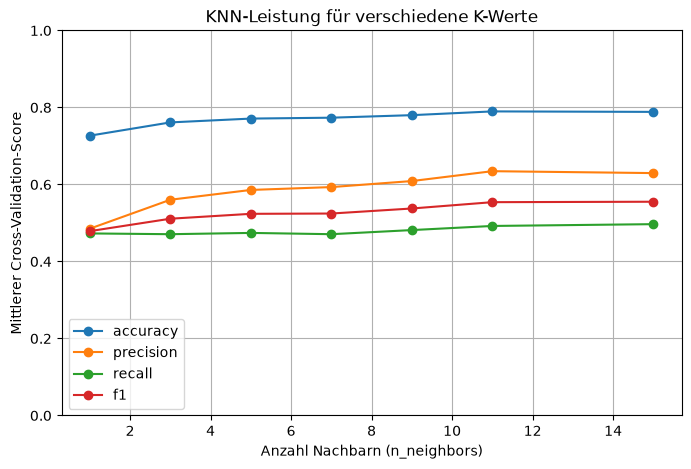

In [152]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

k_values = [1, 3, 5, 7, 9, 11, 15]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = []

for n in k_values:
    model = knn_pipeline.set_params(knn__n_neighbors=n)

    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision",
            "recall": "recall",
            "f1": "f1"
        }
    )

    scores.append({
        "n_neighbors": n,
        "accuracy": cv_scores["test_accuracy"].mean(),
        "precision": cv_scores["test_precision"].mean(),
        "recall": cv_scores["test_recall"].mean(),
        "f1": cv_scores["test_f1"].mean()
    })

results = pd.DataFrame(scores).set_index("n_neighbors")
display(results.round(3))

results[["accuracy", "precision", "recall", "f1"]].plot(
    marker="o", figsize=(8, 5), ylim=(0, 1)
)
plt.xlabel("Anzahl Nachbarn (n_neighbors)")
plt.ylabel("Mittlerer Cross-Validation-Score")
plt.title("KNN-Leistung für verschiedene K-Werte")
plt.grid(True)
plt.show()

In [155]:
best_model = knn_pipeline.set_params(knn__n_neighbors=11)
best_model.fit(X_train, y_train)

y_test_pred = best_model.predict(X_test)

print(f"Bestes K nach mittlerem CV-F1: {11}")
print(f"Test Accuracy:  {accuracy_score(y_test, y_test_pred):.2%}")
print(f"Test Precision: {precision_score(y_test, y_test_pred, zero_division=0):.2%}")
print(f"Test Recall:    {recall_score(y_test, y_test_pred, zero_division=0):.2%}")
print(f"Test F1:        {f1_score(y_test, y_test_pred, zero_division=0):.2%}")

Bestes K nach mittlerem CV-F1: 11
Test Accuracy:  78.71%
Test Precision: 62.42%
Test Recall:    49.73%
Test F1:        55.36%


### Step 7: Analysis and Recommendations
Model accuracy: The selected KNN model (k=11) achieved 78.71% accuracy on the test set. Its churn precision was 62.42%, and churn recall was 49.73%. So when it predicted churn, it was right about 62% of the time, but it identified only about half of the customers who actually churned.

Features that seem important: The feature-selection step selected tenure, MonthlyCharges, InternetService_Fiber optic, Contract_Two year, and PaymentMethod_Electronic check as the five highest-scoring features in the training data. In particular, tenure and contract type are useful areas to examine in your feature-distribution plots. These are model-selected predictors, not proof that they cause churn.

Recommendations: Use the model as an initial way to identify customers who may need attention, not as the sole basis for decisions. Consider testing early-tenure retention support and reviewing contract, pricing, and payment experiences. Because recall is about 50%, the current model will miss many customers who churn; improve and validate it before relying on it for broad outreach.

Limitations: Accuracy alone can be misleading when churn and non-churn groups are imbalanced. This model’s recall shows that it misses about half of actual churners. Results also depend on this train/test split and the historical data; customer behavior may change. Feature selection and correlation indicate association, not causation, and KNN’s predictions depend on feature scaling and the chosen k.

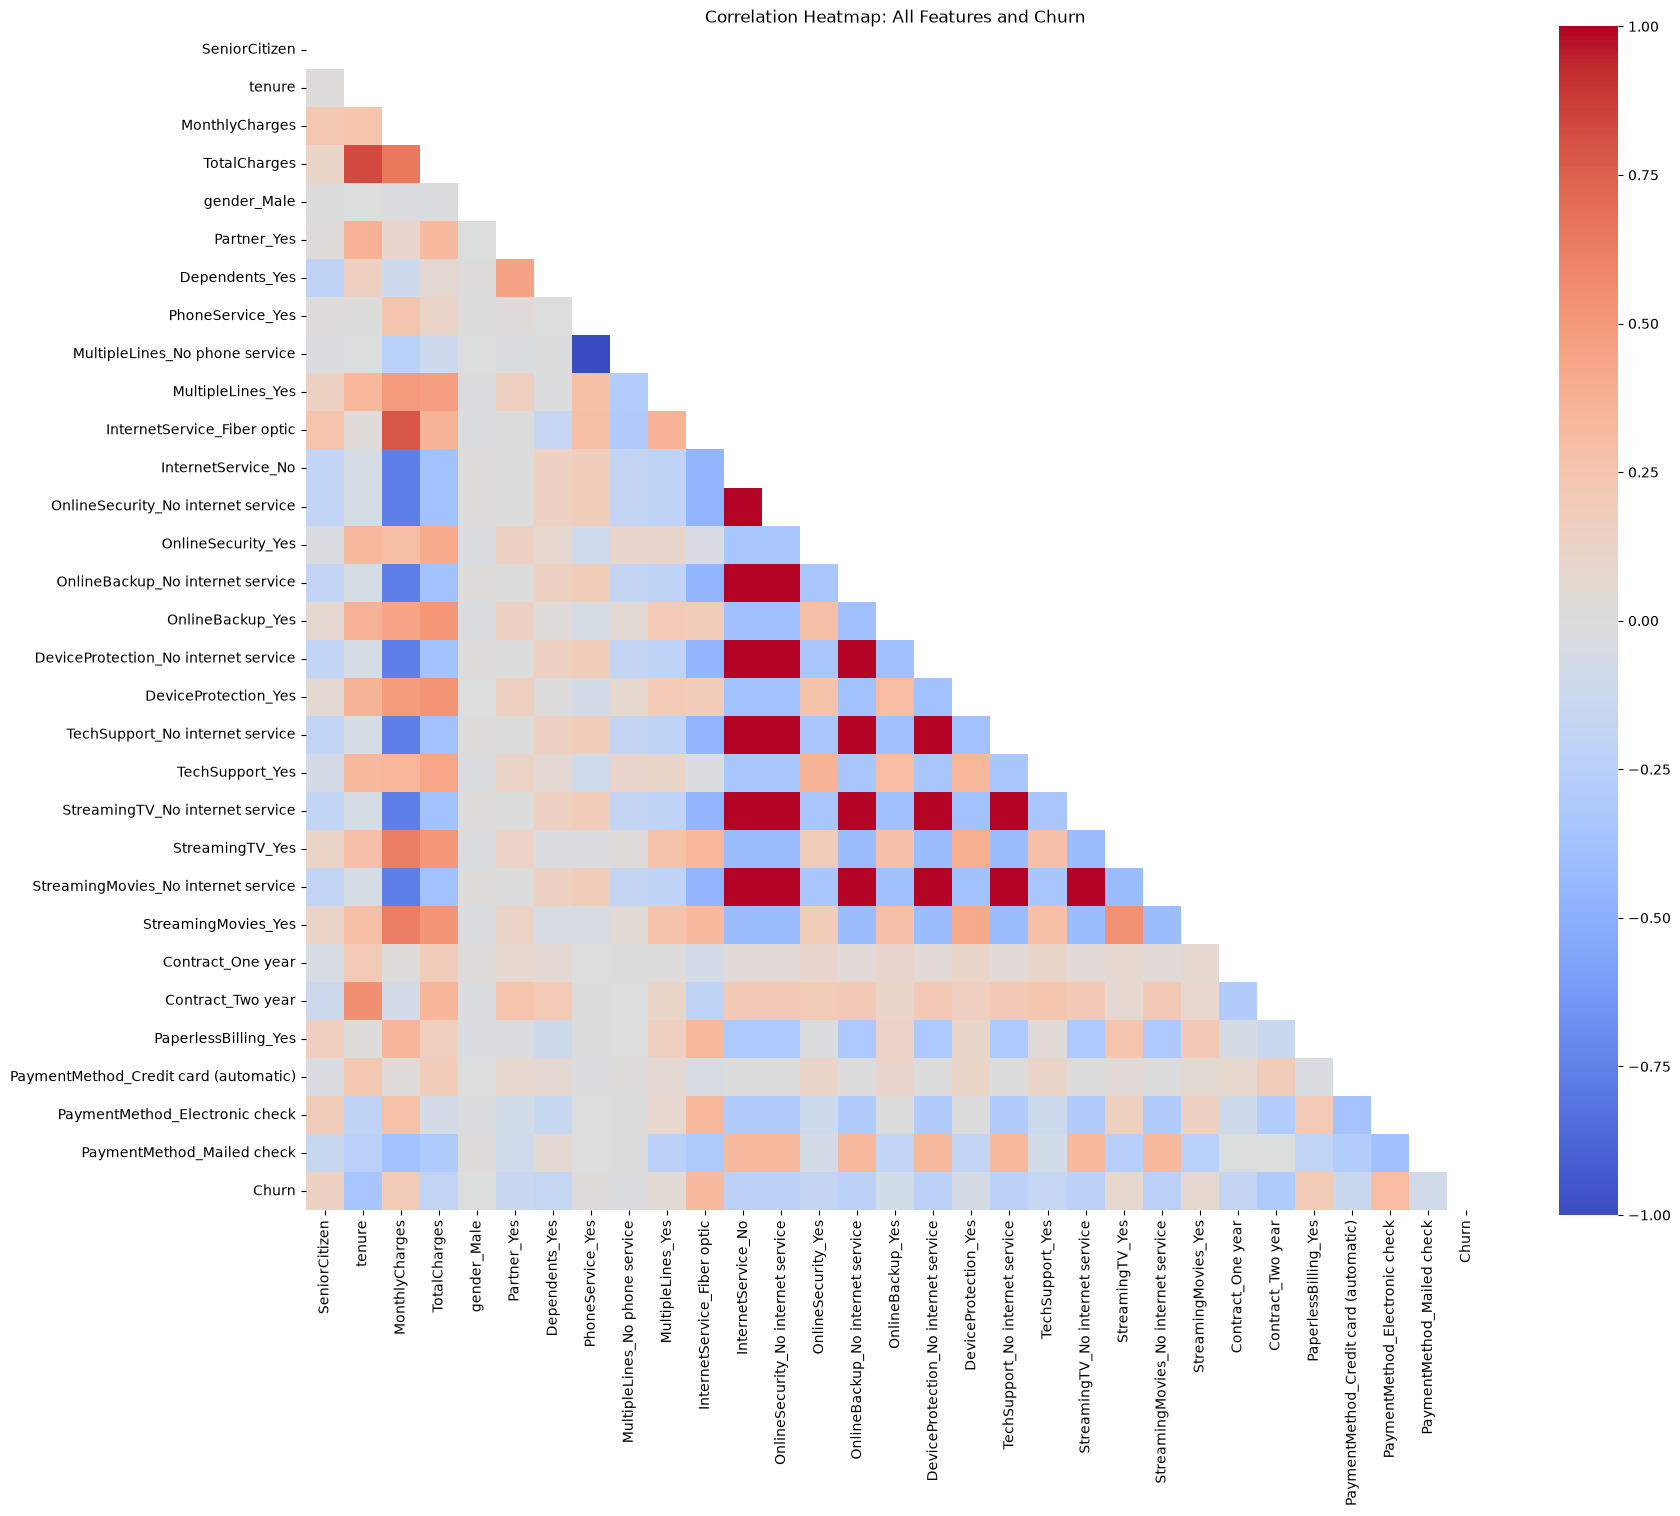

In [157]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

heatmap_data = X_train.copy()
heatmap_data["Churn"] = y_train

corr = heatmap_data.corr(numeric_only=True)

# Hide the duplicate upper half of the correlation matrix
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(18, 15))
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True
)
plt.title("Correlation Heatmap: All Features and Churn")
plt.tight_layout()
plt.show()

In [158]:
churn_correlations = (
    X_train.assign(Churn=y_train)
    .corr(numeric_only=True)["Churn"]
    .drop("Churn")
    .sort_values(ascending=False)
)

display(churn_correlations.to_frame("Correlation with Churn").round(3))

,Correlation with Churn
InternetService_Fiber optic,0.313
PaymentMethod_Electronic check,0.309
MonthlyCharges,0.198
PaperlessBilling_Yes,0.198
SeniorCitizen,0.146
StreamingTV_Yes,0.072
StreamingMovies_Yes,0.064
MultipleLines_Yes,0.044
PhoneService_Yes,0.018
gender_Male,-0.002


Feature relationships: The heatmap suggests churn is associated with shorter customer tenure. Customers with a two-year contract appear less likely to churn, while churn appears more common among customers using fiber-optic internet or electronic-check payments. Monthly charges may also show a positive association with churn. The feature-selection step independently ranked tenure, MonthlyCharges, fiber-optic internet, two-year contracts, and electronic-check payments among its top five predictors. These are associations, not evidence that the features cause churn.